In [3]:
from pathlib import Path

import pandas as pd

# carregando os dados necessários para analisar a alfabetização
caminho = Path("data/gold/base_analitica_alfabetizacao.parquet")

if not caminho.exists():
    caminho = Path("../data/gold/base_analitica_alfabetizacao.parquet")

df = pd.read_parquet(
    caminho,
    columns=["ano", "id_municipio", "rede_codigo", "alfabetizado"],
)

# verificando a base
print("Total de alunos:", len(df))
print("Municípios:", df["id_municipio"].nunique())
print("Valores ausentes no alvo:", df["alfabetizado"].isna().sum())

# calculando a distribuição da alfabetização por ano
distribuicao = (
    df.groupby(["ano", "alfabetizado"])
    .size()
    .reset_index(name="quantidade_alunos")
)

# calculando os percentuais dentro de cada ano
distribuicao["percentual"] = (
    distribuicao["quantidade_alunos"]
    / distribuicao.groupby("ano")["quantidade_alunos"].transform("sum")
    * 100
).round(2)

print("\nDistribuição da alfabetização por ano:")
print(distribuicao.to_string(index=False))

Total de alunos: 3354661
Municípios: 5547
Valores ausentes no alvo: 0

Distribuição da alfabetização por ano:
 ano  alfabetizado  quantidade_alunos  percentual
2023             0             625382       41.61
2023             1             877427       58.39
2024             0             744733       40.22
2024             1            1107119       59.78


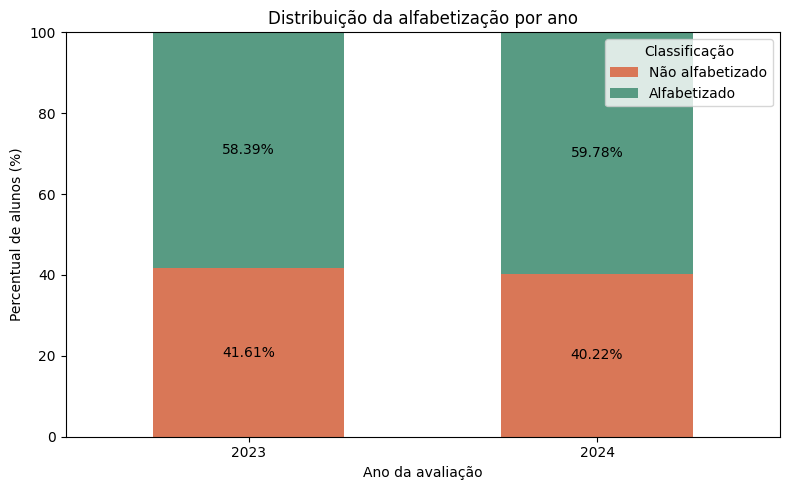

In [4]:
import matplotlib.pyplot as plt

# organizando os percentuais para o gráfico
dados_grafico = distribuicao.pivot(
    index="ano",
    columns="alfabetizado",
    values="percentual",
)

dados_grafico = dados_grafico.rename(
    columns={
        0: "Não alfabetizado",
        1: "Alfabetizado",
    }
)

# criando o gráfico de barras empilhadas
ax = dados_grafico.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["#D97757", "#589B83"],
    width=0.55,
)

# mostrando os percentuais nas barras
for barras in ax.containers:
    ax.bar_label(
        barras,
        label_type="center",
        fmt="%.2f%%",
        fontsize=10,
    )

# ajustando os títulos
ax.set_title("Distribuição da alfabetização por ano")
ax.set_xlabel("Ano da avaliação")
ax.set_ylabel("Percentual de alunos (%)")
ax.set_ylim(0, 100)
ax.set_xticklabels(dados_grafico.index, rotation=0)
ax.legend(title="Classificação")

plt.tight_layout()
plt.show()

In [5]:
# identificando as redes de ensino
redes = {
    "1": "Federal",
    "2": "Estadual",
    "3": "Municipal",
    "4": "Privada",
}

df["rede_ensino"] = df["rede_codigo"].map(redes)

# calculando a distribuição por ano, rede e alfabetização
distribuicao_rede = (
    df.groupby(["ano", "rede_ensino", "alfabetizado"])
    .size()
    .reset_index(name="quantidade_alunos")
)

# calculando o percentual dentro de cada rede e ano
distribuicao_rede["percentual"] = (
    distribuicao_rede["quantidade_alunos"]
    / distribuicao_rede.groupby(["ano", "rede_ensino"])[
        "quantidade_alunos"
    ].transform("sum")
    * 100
).round(2)

print(distribuicao_rede.to_string(index=False))

 ano rede_ensino  alfabetizado  quantidade_alunos  percentual
2023    Estadual             0              50860       38.67
2023    Estadual             1              80662       61.33
2023   Municipal             0             574522       41.90
2023   Municipal             1             796765       58.10
2024    Estadual             0              90314       37.46
2024    Estadual             1             150760       62.54
2024   Municipal             0             654411       40.63
2024   Municipal             1             956343       59.37
2024     Privada             0                  8       33.33
2024     Privada             1                 16       66.67


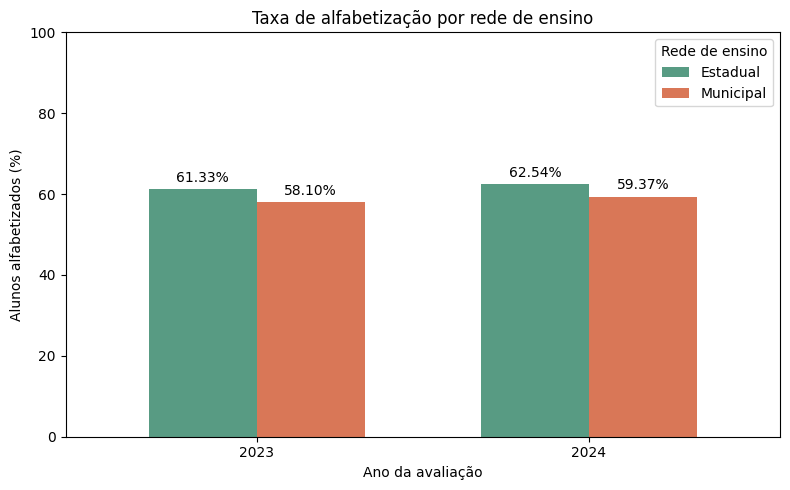

In [6]:
# selecionando as taxas de alfabetização das redes públicas
taxas_rede = distribuicao_rede[
    (distribuicao_rede["alfabetizado"] == 1)
    & (distribuicao_rede["rede_ensino"].isin(["Estadual", "Municipal"]))
]

# organizando os dados para o gráfico
dados_grafico = taxas_rede.pivot(
    index="ano",
    columns="rede_ensino",
    values="percentual",
)

dados_grafico = dados_grafico[["Estadual", "Municipal"]]

# criando o gráfico de comparação
ax = dados_grafico.plot(
    kind="bar",
    figsize=(8, 5),
    color=["#589B83", "#D97757"],
    width=0.65,
)

# mostrando os percentuais sobre as barras
for barras in ax.containers:
    ax.bar_label(
        barras,
        fmt="%.2f%%",
        padding=3,
    )

# ajustando a apresentação
ax.set_title("Taxa de alfabetização por rede de ensino")
ax.set_xlabel("Ano da avaliação")
ax.set_ylabel("Alunos alfabetizados (%)")
ax.set_ylim(0, 100)
ax.set_xticklabels(dados_grafico.index, rotation=0)
ax.legend(title="Rede de ensino")

plt.tight_layout()
plt.show()

In [7]:
# carregando as informações municipais
df_municipios = pd.read_parquet(
    caminho,
    columns=[
        "ano",
        "id_municipio",
        "nome_municipio",
        "alfabetizado",
    ],
)

# selecionando as avaliações de 2024
df_2024 = df_municipios[
    df_municipios["ano"] == 2024
].copy()

# calculando a alfabetização por município
alfabetizacao_municipal = (
    df_2024.groupby(
        ["id_municipio", "nome_municipio"]
    )
    .agg(
        total_alunos=("alfabetizado", "size"),
        taxa_alfabetizacao=("alfabetizado", "mean"),
    )
    .reset_index()
)

# convertendo a proporção para percentual
alfabetizacao_municipal["taxa_alfabetizacao"] *= 100

# verificando a quantidade de alunos por município
print("Total de municípios:", len(alfabetizacao_municipal))

print("\nDistribuição da quantidade de alunos:")
print(alfabetizacao_municipal["total_alunos"].describe())

# selecionando municípios com pelo menos 100 alunos avaliados
municipios_100 = alfabetizacao_municipal[
    alfabetizacao_municipal["total_alunos"] >= 100
].copy()

print("\nMunicípios com pelo menos 100 alunos:", len(municipios_100))

print("\nDistribuição das taxas de alfabetização:")
print(
    municipios_100["taxa_alfabetizacao"]
    .describe()
    .round(2)
)

Total de municípios: 5517

Distribuição da quantidade de alunos:
count     5517.000000
mean       335.662860
std       1655.734764
min          7.000000
25%         53.000000
50%        110.000000
75%        246.000000
max      94373.000000
Name: total_alunos, dtype: float64

Municípios com pelo menos 100 alunos: 2924

Distribuição das taxas de alfabetização:
count    2924.00
mean       61.27
std        17.80
min        15.79
25%        47.86
50%        61.88
75%        74.52
max       100.00
Name: taxa_alfabetizacao, dtype: float64


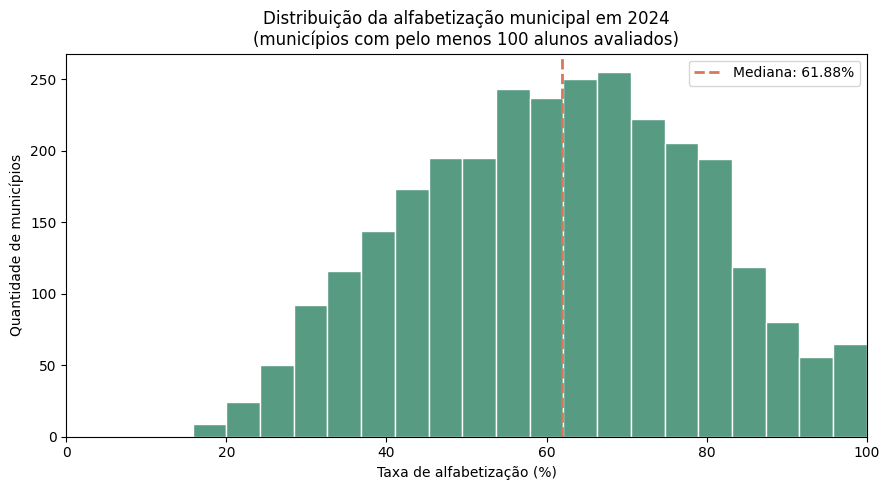

In [8]:
# criando o histograma das taxas municipais
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    municipios_100["taxa_alfabetizacao"],
    bins=20,
    color="#589B83",
    edgecolor="white",
)

# destacando a mediana municipal
mediana = municipios_100["taxa_alfabetizacao"].median()

ax.axvline(
    mediana,
    color="#D97757",
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {mediana:.2f}%",
)

# ajustando o gráfico
ax.set_title(
    "Distribuição da alfabetização municipal em 2024\n"
    "(municípios com pelo menos 100 alunos avaliados)"
)
ax.set_xlabel("Taxa de alfabetização (%)")
ax.set_ylabel("Quantidade de municípios")
ax.set_xlim(0, 100)
ax.legend()

plt.tight_layout()
plt.show()

In [9]:
# carregando a renda municipal
renda = pd.read_parquet(
    caminho,
    columns=[
        "ano",
        "id_municipio",
        "renda_mediana_per_capita",
    ],
)

# selecionando a renda dos municípios em 2024
renda_2024 = (
    renda[renda["ano"] == 2024]
    [["id_municipio", "renda_mediana_per_capita"]]
    .drop_duplicates()
)

# verificando se existe apenas uma renda por município
if renda_2024["id_municipio"].duplicated().any():
    raise ValueError("Municípios com valores de renda diferentes.")

# relacionando renda e alfabetização municipal
municipios_renda = municipios_100.merge(
    renda_2024,
    on="id_municipio",
    how="left",
    validate="one_to_one",
)

# verificando a qualidade da integração
print("Municípios analisados:", len(municipios_renda))
print(
    "Valores de renda ausentes:",
    municipios_renda["renda_mediana_per_capita"].isna().sum(),
)

# calculando as correlações
pearson = municipios_renda[
    ["renda_mediana_per_capita", "taxa_alfabetizacao"]
].corr(method="pearson").iloc[0, 1]

spearman = municipios_renda[
    ["renda_mediana_per_capita", "taxa_alfabetizacao"]
].corr(method="spearman").iloc[0, 1]

print(f"\nCorrelação de Pearson: {pearson:.4f}")
print(f"Correlação de Spearman: {spearman:.4f}")

Municípios analisados: 2924
Valores de renda ausentes: 0

Correlação de Pearson: 0.2227
Correlação de Spearman: 0.2327


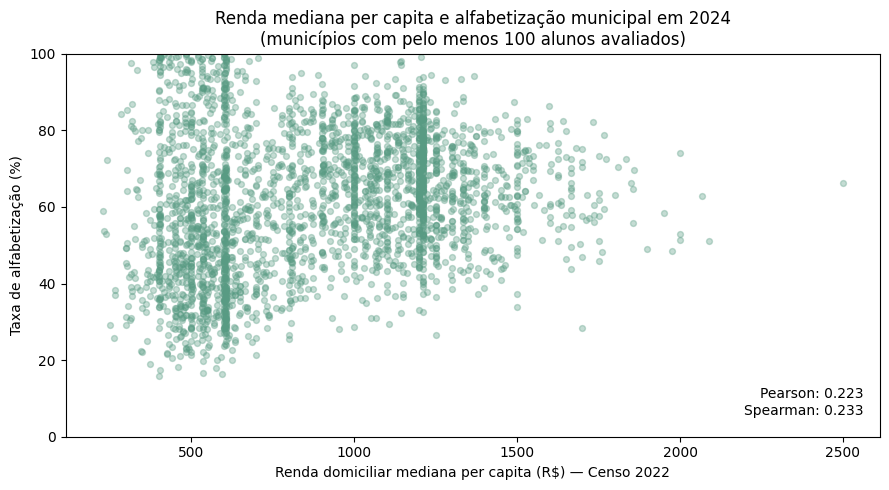

In [10]:
# criando o gráfico de dispersão
fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    municipios_renda["renda_mediana_per_capita"],
    municipios_renda["taxa_alfabetizacao"],
    color="#589B83",
    alpha=0.35,
    s=18,
)

# ajustando os títulos
ax.set_title(
    "Renda mediana per capita e alfabetização municipal em 2024\n"
    "(municípios com pelo menos 100 alunos avaliados)"
)

ax.set_xlabel("Renda domiciliar mediana per capita (R$) — Censo 2022")
ax.set_ylabel("Taxa de alfabetização (%)")
ax.set_ylim(0, 100)

# mostrando os coeficientes no gráfico
ax.text(
    0.98,
    0.05,
    f"Pearson: {pearson:.3f}\nSpearman: {spearman:.3f}",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"},
)

plt.tight_layout()
plt.show()

In [11]:
# selecionando os indicadores de infraestrutura escolar
indicadores_educacionais = [
    "pct_escolas_com_biblioteca",
    "pct_escolas_com_internet_alunos",
    "pct_escolas_com_internet_aprendizagem",
    "pct_escolas_com_laboratorio_informatica",
]

# carregando os indicadores educacionais
educacao = pd.read_parquet(
    caminho,
    columns=["ano", "id_municipio", *indicadores_educacionais],
)

# selecionando os municípios de 2024
educacao_2024 = (
    educacao[educacao["ano"] == 2024]
    .drop(columns="ano")
    .drop_duplicates()
)

# verificando se existe uma linha por município
if educacao_2024["id_municipio"].duplicated().any():
    raise ValueError("Indicadores diferentes para o mesmo município.")

# relacionando infraestrutura e alfabetização
municipios_educacao = municipios_100.merge(
    educacao_2024,
    on="id_municipio",
    how="left",
    validate="one_to_one",
)

# verificando a integração
print("Municípios analisados:", len(municipios_educacao))

print(
    "Indicadores ausentes:",
    municipios_educacao[indicadores_educacionais].isna().sum().sum(),
)

# calculando a correlação de Spearman
correlacoes = (
    municipios_educacao[
        ["taxa_alfabetizacao", *indicadores_educacionais]
    ]
    .corr(method="spearman")["taxa_alfabetizacao"]
    .drop("taxa_alfabetizacao")
    .sort_values(ascending=False)
)

print("\nCorrelações com a taxa de alfabetização:")
print(correlacoes.round(4).to_string())

Municípios analisados: 2924
Indicadores ausentes: 0

Correlações com a taxa de alfabetização:
pct_escolas_com_biblioteca                 0.3060
pct_escolas_com_internet_aprendizagem      0.2021
pct_escolas_com_laboratorio_informatica    0.1754
pct_escolas_com_internet_alunos            0.1034


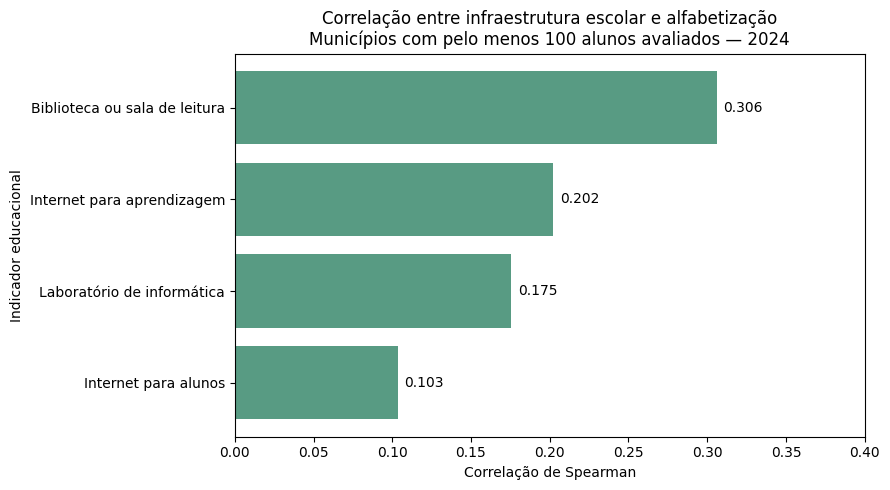

In [12]:
# organizando os nomes dos indicadores
nomes_indicadores = {
    "pct_escolas_com_biblioteca": "Biblioteca ou sala de leitura",
    "pct_escolas_com_internet_aprendizagem": "Internet para aprendizagem",
    "pct_escolas_com_laboratorio_informatica": "Laboratório de informática",
    "pct_escolas_com_internet_alunos": "Internet para alunos",
}

dados_grafico = correlacoes.rename(
    index=nomes_indicadores
).sort_values()

# criando o gráfico de correlações
fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.barh(
    dados_grafico.index,
    dados_grafico.values,
    color="#589B83",
)

# mostrando os coeficientes nas barras
ax.bar_label(
    barras,
    fmt="%.3f",
    padding=5,
)

# ajustando o gráfico
ax.set_title(
    "Correlação entre infraestrutura escolar e alfabetização\n"
    "Municípios com pelo menos 100 alunos avaliados — 2024"
)

ax.set_xlabel("Correlação de Spearman")
ax.set_ylabel("Indicador educacional")
ax.set_xlim(0, 0.4)

plt.tight_layout()
plt.show()

In [13]:
# relacionando os indicadores educacionais com a renda municipal
analise_biblioteca = municipios_educacao.merge(
    municipios_renda[
        ["id_municipio", "renda_mediana_per_capita"]
    ],
    on="id_municipio",
    how="inner",
    validate="one_to_one",
)

# dividindo os municípios em quatro grupos de renda
analise_biblioteca["faixa_renda"] = pd.qcut(
    analise_biblioteca["renda_mediana_per_capita"],
    q=4,
    labels=[
        "Renda mais baixa",
        "Renda baixa-intermediária",
        "Renda alta-intermediária",
        "Renda mais alta",
    ],
)

# calculando a correlação dentro de cada faixa
resultados = []

for faixa, grupo in analise_biblioteca.groupby(
    "faixa_renda",
    observed=True,
):
    correlacao = grupo[
        [
            "pct_escolas_com_biblioteca",
            "taxa_alfabetizacao",
        ]
    ].corr(method="spearman").iloc[0, 1]

    resultados.append({
        "faixa_renda": faixa,
        "municipios": len(grupo),
        "correlacao_biblioteca": round(correlacao, 4),
    })

resultado_faixas = pd.DataFrame(resultados)

print(resultado_faixas.to_string(index=False))

              faixa_renda  municipios  correlacao_biblioteca
         Renda mais baixa         740                 0.2333
Renda baixa-intermediária         722                 0.2802
 Renda alta-intermediária         801                 0.1318
          Renda mais alta         661                 0.0129


In [14]:
# verificando a distribuição da infraestrutura por faixa de renda
resumo_bibliotecas = (
    analise_biblioteca.groupby("faixa_renda", observed=True)
    .agg(
        municipios=("id_municipio", "size"),
        media_bibliotecas=("pct_escolas_com_biblioteca", "mean"),
        desvio_bibliotecas=("pct_escolas_com_biblioteca", "std"),
        media_alfabetizacao=("taxa_alfabetizacao", "mean"),
    )
    .round(2)
)

print(resumo_bibliotecas.to_string())

                           municipios  media_bibliotecas  desvio_bibliotecas  media_alfabetizacao
faixa_renda                                                                                      
Renda mais baixa                  740              29.58               25.02                56.58
Renda baixa-intermediária         722              42.62               25.98                56.53
Renda alta-intermediária          801              65.61               26.98                66.56
Renda mais alta                   661               77.2               22.26                65.28


In [15]:
# carregando as metas municipais da Gold da Fase 2
metas = pd.read_parquet(
    caminho.parent / "comparativo_metas_municipio_brasil.parquet"
)

# verificando a estrutura da tabela
print("Registros:", len(metas))
print("\nColunas:")
print(metas.columns.tolist())

print("\nTipos de dados:")
print(metas.dtypes.to_string())

print("\nPrimeiros registros:")
print(metas.head(3).to_string(index=False))

Registros: 10704

Colunas:
['ano', 'id_municipio', 'rede_descricao', 'taxa_alfabetizacao', 'meta_referencia_ano', 'distancia_para_meta_municipio', 'status_meta_municipio', 'taxa_alfabetizacao_brasil', 'meta_referencia_brasil', 'diferenca_taxa_municipio_brasil', 'nivel_alfabetizacao', 'percentual_participacao', 'percentual_participacao_brasil']

Tipos de dados:
ano                                         int64
id_municipio                       string[python]
rede_descricao                     string[python]
taxa_alfabetizacao                        float64
meta_referencia_ano                       float64
distancia_para_meta_municipio             float64
status_meta_municipio                      object
taxa_alfabetizacao_brasil                 float64
meta_referencia_brasil                    float64
diferenca_taxa_municipio_brasil           float64
nivel_alfabetizacao                       float64
percentual_participacao                   float64
percentual_participacao_brasil       

In [16]:
# verificando quantos municípios possuem resultados e metas por ano e rede
cobertura_metas = (
    metas.groupby(["ano", "rede_descricao"])
    .agg(
        registros=("id_municipio", "size"),
        municipios=("id_municipio", "nunique"),
        com_resultado=("taxa_alfabetizacao", "count"),
        com_meta=("meta_referencia_ano", "count"),
        com_distancia=("distancia_para_meta_municipio", "count"),
    )
    .reset_index()
)

print("Cobertura das metas por ano e rede:")
print(cobertura_metas.to_string(index=False))

# verificando possíveis registros duplicados
duplicidades = metas.duplicated(
    subset=["ano", "id_municipio", "rede_descricao"]
).sum()

print("\nRegistros duplicados:", duplicidades)

# verificando as situações de cumprimento das metas
print("\nDistribuição dos status das metas:")
print(
    pd.crosstab(
        metas["ano"],
        metas["status_meta_municipio"],
        dropna=False,
    ).to_string()
)

Cobertura das metas por ano e rede:
 ano rede_descricao  registros  municipios  com_resultado  com_meta  com_distancia
2023      Municipal       5352        5352           5232         0              0
2024      Municipal       5352        5352           5352      5232           5232

Registros duplicados: 0

Distribuição dos status das metas:
status_meta_municipio  abaixo_da_meta  atingiu_ou_superou_meta  sem_meta_ou_resultado
ano                                                                                  
2023                                0                        0                   5352
2024                             2444                     2788                    120


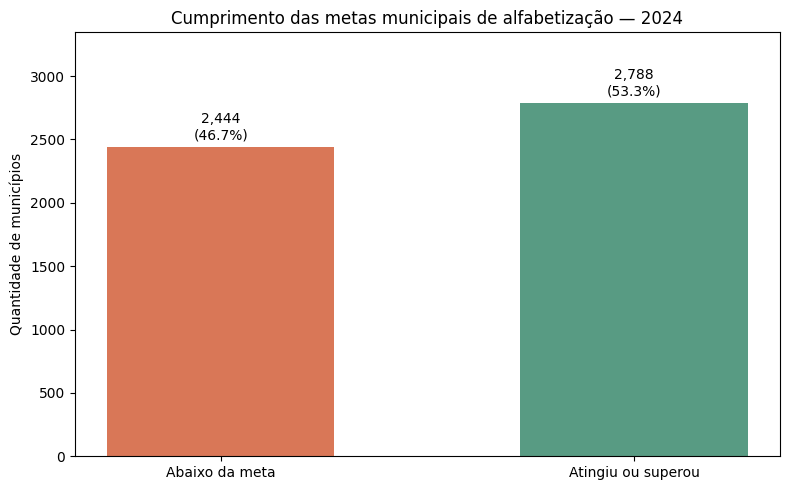

In [17]:
# selecionando apenas 2024 e municípios com comparação válida
metas_2024 = metas[
    (metas["ano"] == 2024)
    & metas["taxa_alfabetizacao"].notna()
    & metas["meta_referencia_ano"].notna()
    & metas["distancia_para_meta_municipio"].notna()
].copy()

# contando municípios por situação
contagem_status = (
    metas_2024["status_meta_municipio"]
    .value_counts()
    .reindex([
        "abaixo_da_meta",
        "atingiu_ou_superou_meta",
    ], fill_value=0)
)

# calculando os percentuais
percentuais = contagem_status / contagem_status.sum() * 100

# criando o gráfico
fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    ["Abaixo da meta", "Atingiu ou superou"],
    contagem_status.values,
    color=["#D97757", "#589B83"],
    width=0.55,
)

# mostrando quantidade e percentual acima de cada barra
for barra, quantidade, percentual in zip(
    barras,
    contagem_status.values,
    percentuais.values,
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 35,
        f"{quantidade:,}\n({percentual:.1f}%)",
        ha="center",
        va="bottom",
    )

ax.set_title("Cumprimento das metas municipais de alfabetização — 2024")
ax.set_ylabel("Quantidade de municípios")
ax.set_ylim(0, contagem_status.max() * 1.2)

plt.tight_layout()
plt.show()

In [18]:
# selecionando os municípios que ficaram abaixo da meta
municipios_abaixo = metas_2024[
    metas_2024["status_meta_municipio"] == "abaixo_da_meta"
].copy()

# calculando quantos pontos percentuais faltaram para atingir a meta
municipios_abaixo["deficit_pp"] = (
    municipios_abaixo["meta_referencia_ano"]
    - municipios_abaixo["taxa_alfabetizacao"]
)

# verificando o tamanho dos déficits
print("Municípios abaixo da meta:", len(municipios_abaixo))

print("\nDistribuição do déficit em pontos percentuais:")
print(
    municipios_abaixo["deficit_pp"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90])
    .round(2)
)

# verificando quantos municípios apresentam déficits maiores
print("\nMunicípios com déficit superior a 5 p.p.:",
      (municipios_abaixo["deficit_pp"] > 5).sum())

print("Municípios com déficit superior a 10 p.p.:",
      (municipios_abaixo["deficit_pp"] > 10).sum())

print("Municípios com déficit superior a 20 p.p.:",
      (municipios_abaixo["deficit_pp"] > 20).sum())

Municípios abaixo da meta: 2444

Distribuição do déficit em pontos percentuais:
count    2444.00
mean       11.28
std         9.91
min         0.02
25%         3.91
50%         8.60
75%        15.86
90%        25.44
max        68.90
Name: deficit_pp, dtype: float64

Municípios com déficit superior a 5 p.p.: 1671
Municípios com déficit superior a 10 p.p.: 1066
Municípios com déficit superior a 20 p.p.: 430


In [19]:
# selecionando os 10 municípios com maiores déficits
maiores_deficits = (
    municipios_abaixo.nlargest(10, "deficit_pp")
    [
        [
            "id_municipio",
            "taxa_alfabetizacao",
            "meta_referencia_ano",
            "deficit_pp",
            "percentual_participacao",
        ]
    ]
    .round(2)
)

print("10 maiores déficits municipais em 2024:")
print(maiores_deficits.to_string(index=False))

# verificando a participação entre todos os municípios abaixo da meta
print("\nParticipação dos municípios abaixo da meta:")
print(
    municipios_abaixo["percentual_participacao"]
    .describe()
    .round(2)
)

10 maiores déficits municipais em 2024:
id_municipio  taxa_alfabetizacao  meta_referencia_ano  deficit_pp  percentual_participacao
     4320453               11.10                80.00       68.90                   100.00
     4301073               18.20                80.00       61.80                    84.62
     4319752               25.00                80.00       55.00                   100.00
     4310850               25.00                80.00       55.00                   100.00
     4319208                7.10                61.56       54.46                    82.35
     4306700               26.70                80.00       53.30                    93.75
     4302584               27.30                80.00       52.70                   100.00
     4313334               28.00                80.00       52.00                    96.15
     1713601               19.71                71.56       51.85                    81.01
     4320354               23.50                74


## Conclusões da análise exploratória

A análise exploratória teve como objetivo compreender a distribuição da alfabetização entre os alunos avaliados em 2023 e 2024, investigar diferenças territoriais e educacionais e identificar possíveis associações com características socioeconômicas e infraestrutura escolar.

### 1. Distribuição da alfabetização

A base analítica contém 3.354.661 registros individuais de alunos com avaliações válidas.

- **2023:** 58,39% dos alunos avaliados foram classificados como alfabetizados.
- **2024:** 59,78% dos alunos avaliados foram classificados como alfabetizados.

A diferença observada foi de 1,39 ponto percentual. Entretanto, como a cobertura das avaliações varia entre os anos, essa diferença não deve ser interpretada automaticamente como uma evolução nacional da alfabetização.

### 2. Diferenças entre redes de ensino

Em 2024, a rede estadual apresentou taxa de alfabetização de 62,54%, enquanto a rede municipal apresentou 59,37%.

Essa diferença é descritiva e não permite concluir que uma rede de ensino seja mais eficaz que a outra, pois as populações avaliadas podem apresentar características distintas.

### 3. Desigualdades municipais

Em 2024, foram identificados 5.517 municípios com alunos avaliados.

Para reduzir a influência de taxas calculadas sobre grupos muito pequenos, a análise exploratória municipal considerou 2.924 municípios com pelo menos 100 alunos avaliados.

Nesse conjunto, a taxa mediana de alfabetização foi de 61,88%, com desvio-padrão de 17,80 pontos percentuais.

Os resultados indicam diferenças expressivas entre municípios e justificam a investigação de fatores territoriais e educacionais associados à alfabetização.

### 4. Renda e alfabetização

A renda domiciliar mediana per capita apresentou associação positiva fraca com a taxa municipal de alfabetização em 2024:

- Pearson: 0,2227.
- Spearman: 0,2327.

Portanto, municípios de maior renda tenderam a apresentar taxas de alfabetização mais elevadas, mas a renda isoladamente não explica toda a variação observada.

A análise é retrospectiva: os dados de renda referentes ao Censo 2022 foram divulgados em 2025 e não devem ser utilizados sem considerar sua disponibilidade temporal na modelagem.

### 5. Infraestrutura escolar

Entre os indicadores educacionais analisados, a proporção de escolas públicas com biblioteca ou sala de leitura apresentou a maior correlação de Spearman com a alfabetização municipal (0,3060).

Entretanto, essa associação variou entre as faixas de renda:

- Renda mais baixa: 0,2333.
- Renda baixa-intermediária: 0,2802.
- Renda alta-intermediária: 0,1318.
- Renda mais alta: 0,0129.

Os resultados indicam que a relação entre infraestrutura e alfabetização não é uniforme entre os grupos socioeconômicos.

Essas associações não demonstram relações causais.

### 6. Cumprimento das metas municipais

Na tabela Gold de metas municipais, foram identificados 5.232 municípios com resultados e metas comparáveis em 2024, considerando a rede municipal.

- 2.788 municípios (53,3%) atingiram ou superaram a meta.
- 2.444 municípios (46,7%) ficaram abaixo da meta.
- Entre os municípios abaixo da meta, o déficit mediano foi de 8,60 pontos percentuais.
- 430 municípios apresentaram déficit superior a 20 pontos percentuais.

A participação média na avaliação entre os municípios abaixo da meta foi de 90,03%.

Esses resultados permitem identificar descumprimentos observados, mas não representam previsões de risco futuro.

### 7. Implicações para a modelagem

Os resultados da EDA orientam as próximas decisões:

1. Desenvolver um modelo supervisionado de classificação binária no nível do aluno.
2. Avaliar o uso de variáveis territoriais e educacionais como preditoras.
3. Investigar a generalização temporal do modelo entre 2023 e 2024.
4. Evitar variáveis que provoquem vazamento de informação, especialmente a proficiência utilizada na definição do alvo.
5. Considerar as limitações de utilizar indicadores municipais para prever resultados individuais.
6. Utilizar as metas educacionais na análise estratégica, distinguindo resultados observados de previsões.

**Limitação geral:** as análises apresentadas são descritivas e não causais. Os indicadores municipais não representam necessariamente as condições individuais de cada aluno. Os percentuais calculados diretamente dos microdados não devem ser confundidos com os indicadores oficiais agregados, que podem empregar ponderações e critérios próprios.

A próxima etapa será a auditoria das variáveis e a preparação da pipeline de Machine Learning.